<a href="https://colab.research.google.com/github/oliviaguo1234/HiMCM-2026/blob/main/HiMCM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1

Variables to consider:
* Air temperature
* Humidity
* Electricity price
* Power (kW)
* Cooled area

# 2.a

Variables for part 2:
* Air temperature
* Humidity
* Electricity price
* Power (kW)
* Cooled area
* Visitor count/number of people
* Operating time

E = A * N * P / t

$$
CES = \frac{N \times ΔSET}{E}
$$


### Variable Definitions

- **A – Shelter Size Factor:** Accounts for the area being cooled. Larger shelters receive a higher factor if the system can effectively cool the entire space.

- **C – Climate Factor:** Measures how well the cooling system works in the local climate. For example, evaporative coolers receive a higher factor in dry climates.

- **P – People Factor:** Represents the number of people benefiting from the cooling system.

- **K – Comfort Factor:** Measures how comfortable people feel. Fans receive credit for perceived cooling, while evaporative coolers receive credit for lowering actual air temperature.

- **E – Energy Use:** The electricity consumed in kilowatts (kW).

- **R – Energy Cost Factor:** Represents the cost of electricity.

- **T - Operating Time:** operating time.

Passenger Density:
D = N / A
* D = density
* N = number of passengers
* A = area

UTCI: thermal stress that outdoor environmental conditions place on the human body
* Delta UTCI = UTCIbefore - UTCIafter
* UTCI = Ta + f(Ta, Tmrt, v, e)
* Ta = air temperature
* Tmrt = median radiant temperature
* v = wind speed measured at 10m
* e = water vapor pressure
* f = polynominal function

# 2b

- Changed the model from including passenger density and area to this version instead of E = N * deltaUTCI / P
- We also decided to not use deltaUTCI, instead using SET

In [111]:
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt

from scipy.optimize import minimize

In [112]:

%pip install -q pythermalcomfort #calculation for mean radiant temperature
from pythermalcomfort.environment import mean_radiant_tmp

cooling_system = input('Choose cooling system (fan, evaporative, or large evaporative): ').strip().lower()

if cooling_system == 'fan':
    max_temp_drop = 0
    e = 0.25
elif cooling_system == 'evaporative':
    max_temp_drop = 5
    e = 1.2
elif cooling_system == 'large evaporative':
    max_temp_drop = 8
    e = 2.5
else:
    raise ValueError('Invalid cooling system')

#environment conditions
tg_before = 38 #global temperature in celsius
tdb_before = 32 #air temperature in celsius
v_before = 1.0 #air speed

#calculate mean radiant temperature
mrt_before = mean_radiant_tmp(
    tg=tg_before,
    tdb=tdb_before,
    v=v_before
)


if cooling_system == "fan":
    tdb_after = tdb_before
    v_after = v_before + 2.0
    mrt_after = mrt_before

else:
    requested_temp_drop = float(input(
        "Enter expected air temperature reduction: "
    ))
    actual_temp_drop = max(
        0, min(requested_temp_drop, max_temp_drop)
    )
    tdb_after = tdb_before - actual_temp_drop
    v_after = v_before
    mrt_after = mrt_before


print('Mean Radiant Temperature before:', mrt_before)
print('Mean Radiant Temperature after:', mrt_after)

Choose cooling system (fan, evaporative, or large evaporative): fan
Mean Radiant Temperature before: 52.51990628047321
Mean Radiant Temperature after: 52.51990628047321


In [113]:
!pip install pythermalcomfort
from pythermalcomfort.models import two_nodes_gagge

#environmental conditions before
air_temperature_before = tdb_before #in degrees Celcius
mean_radiant_temperature_before = mrt_before #in degrees Celsius
wind_speed_before = 1.0 #in m/s
relative_humidity_before = 50 #as a percent

#environmental conditions after
air_temperature_after = tdb_after
mean_radiant_temperature_after = mrt_after
wind_speed_after = v_after  #assume that wind speed of fan is 2 m/s
relative_humidity_after = 50

before = two_nodes_gagge(
    tdb=air_temperature_before,
    tr=mean_radiant_temperature_before,
    v=wind_speed_before,
    rh=relative_humidity_before,
    met=1.2,
    clo=0.5
)

after = two_nodes_gagge(
    tdb=air_temperature_after,
    tr=mean_radiant_temperature_after,
    v=wind_speed_after,
    rh=relative_humidity_after,
    met=1.2,
    clo=0.5
)

deltaSET = before.set - after.set

print('SET Before:', before.set)
print('SET After:', after.set)
print('SET Reduction:', deltaSET)

SET Before: 33.91
SET After: 31.26
SET Reduction: 2.649999999999995


In [114]:
n = 5 #number of passengers
#deltaSET
#e = energy use
ces = (n * deltaSET) / (e)

print('CES =', ces)

CES = 52.9999999999999


# 3: apply the model

In [115]:
#use a principal component analysis and k-means machine learning model
#assume that each fan can cover 100 m^2 area, assume that r = 5.75

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#features for PCA
features = [
    'Air.temperature',
    'Relative.humidity',
    'Wind.speed',
    'Radiant.temperature'
]

dataset = pd.read_excel(
    '/content/dataset.xlsx',
    sheet_name='UTHECA_USE'
)

X = dataset[features]

#standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#PCA model
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print('Explained variance ratio:', pca.explained_variance_ratio_)
print('Cumulative explained variance:', np.cumsum(pca.explained_variance_ratio_))


Explained variance ratio: [0.59798572 0.25488051 0.1110126  0.03612117]
Cumulative explained variance: [0.59798572 0.85286623 0.96387883 1.        ]


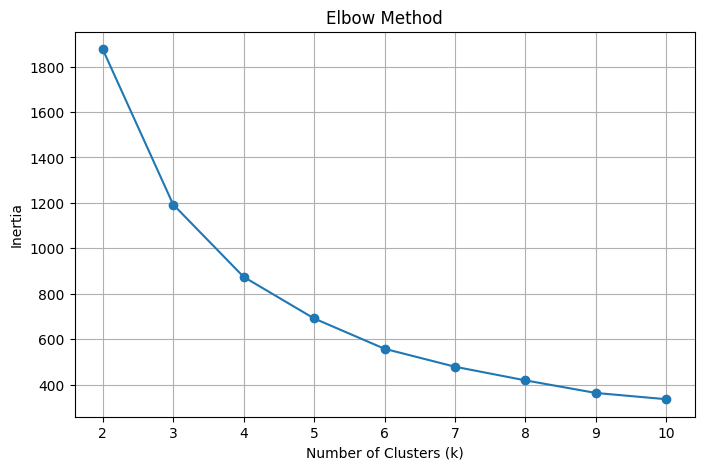

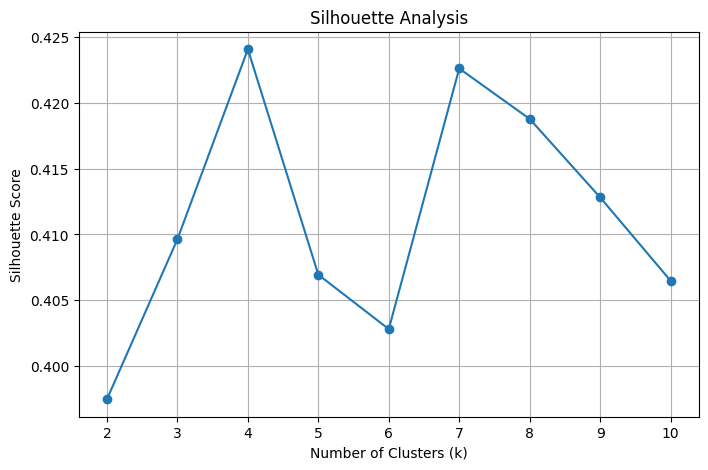

In [116]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
inertias = []
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10)

    clusters = kmeans.fit_predict(X_pca[:, :2])

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_pca[:, :2], clusters)
    )

#plot
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertias, marker='o')

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis')
plt.grid(True)
plt.show()
#inertia is how far data points are from the cluster/center
#elbow shows optimal spot for the number of clusters to use

In [117]:
k = 3

#create a k means model
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_pca[:, :2])
dataset['Cluster'] = clusters

print(dataset[['Air.temperature',
               'Relative.humidity',
               'Wind.speed',
               'Radiant.temperature',
               'Cluster']].head())

   Air.temperature  Relative.humidity  Wind.speed  Radiant.temperature  \
0             32.6               20.0        1.30            39.295175   
1             33.7               25.9        0.67            56.860994   
2             33.0               20.0        0.40            48.378335   
3             32.8               19.9        0.16            43.773383   
4             31.6               20.7        1.31            46.930957   

   Cluster  
0        2  
1        2  
2        2  
3        0  
4        2  


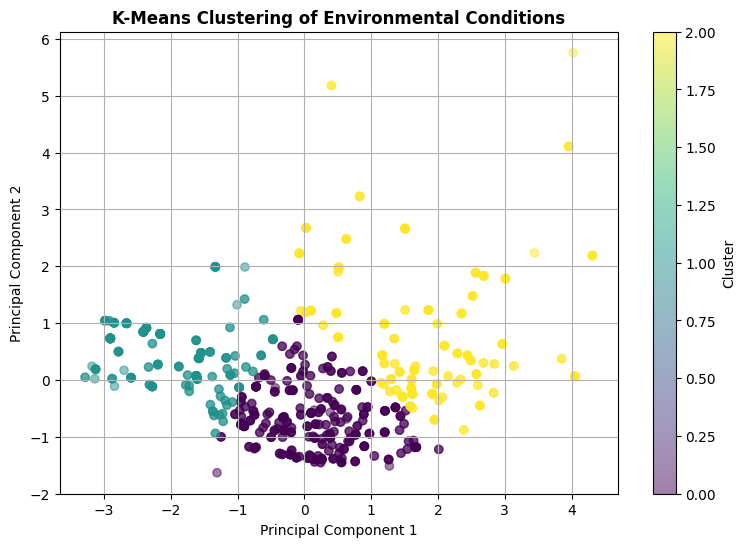

In [118]:
# Plot environmental clusters
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    alpha=0.5
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Clustering of Environmental Conditions', weight='bold')

plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()

In [119]:
cluster_summary = dataset.groupby('Cluster')[features].mean()

print(cluster_summary)

         Air.temperature  Relative.humidity  Wind.speed  Radiant.temperature
Cluster                                                                     
0              28.279114          29.062869    0.604873            28.375486
1              22.424906          51.777358    0.725019            24.142301
2              30.522400          27.989200    2.098080            40.597801


# Other Visualizations

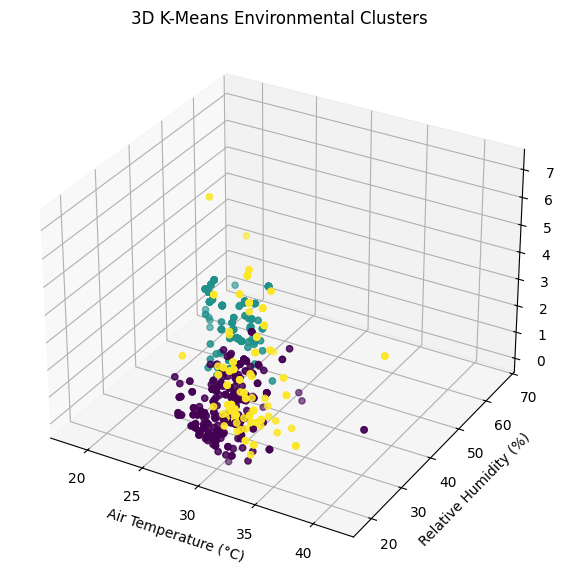

In [120]:
fig = plt.figure(figsize=(9, 7))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    dataset["Air.temperature"],
    dataset["Relative.humidity"],
    dataset["Wind.speed"],
    c=dataset["Cluster"],
    cmap="viridis",
    alpha=0.6
)

ax.set_xlabel("Air Temperature (°C)")
ax.set_ylabel("Relative Humidity (%)")
ax.set_zlabel("Wind Speed (m/s)")

ax.set_title("3D K-Means Environmental Clusters")

plt.show()

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/usr/local/lib/python3.13/dist-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


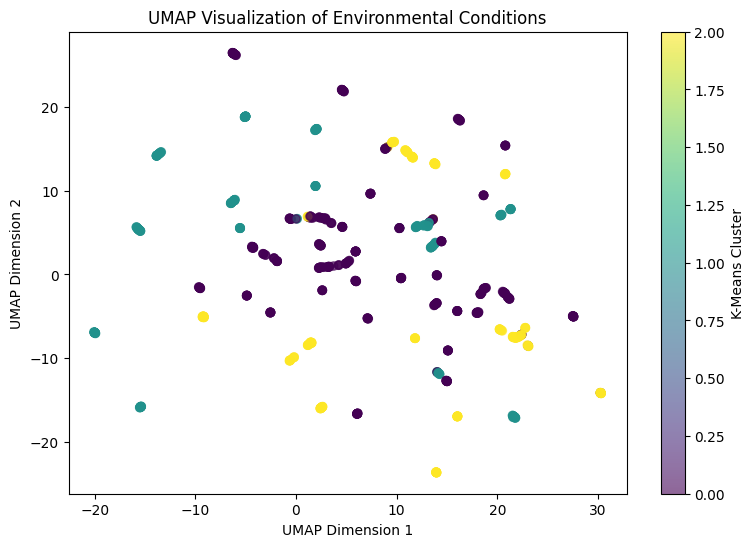

In [121]:
!pip install umap-learn
import umap
import matplotlib.pyplot as plt

#fit environmental data to 2D
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

X_umap = reducer.fit_transform(X_scaled)

#visualization
plt.figure(figsize=(9, 6))

plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=clusters,
    cmap='viridis',
    alpha=0.6
)

plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.title("UMAP Visualization of Environmental Conditions")
plt.colorbar(label="K-Means Cluster")

plt.show()